In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Environment and Distribution Shift

The test error of that section tells us how
well a classifier will do on new data, provided the new data come from the
distribution of the test set. After deployment this condition often fails,
even when the model has no influence on the data: a hospital buys a new
scanner, an epidemic changes which diseases patients have, and the meaning
of words drifts. The test set then gives no warning. Can we still predict,
or even improve, how the model does on the data it now sees?

The model can also change the data itself. Suppose that a bank trains a
model to predict which loan applicants will repay, and the model finds that
applicants who wear Oxfords tend to repay while applicants who wear sneakers
tend to default. The model scores well on held-out applications, so the bank
approves everyone in Oxfords and declines everyone in sneakers. Applicants
soon notice, everyone starts wearing Oxfords, and the fraction who repay
stays what it was. The model was accurate on the data it was tested on and
is useless on the data it now sees, because using it changed the data. This
is an instance of *Goodhart's law*: when a measure becomes a target, it
ceases to be a good measure.

We first show that nothing carries over from the old distribution to the new
one unless we assume something about how the two are related, and we sort the
common assumptions by which part of the joint distribution of inputs and
labels they keep fixed. Under two of them, unlabeled examples from the new
distribution suffice to correct training by reweighting the training examples;
the third needs new labels. We end with models whose decisions change their
own data, where statistical correction stops and questions of policy begin.

## Types of Distribution Shift

To say what can be corrected when the data change, we first need names for
the two distributions and for what changes between them. We train on labeled
examples drawn from a *source distribution* with density $p_S(\mathbf{x}, y)$
and deploy the model on examples drawn from a *target distribution* with
density $p_T(\mathbf{x}, y)$, whose inputs we observe but, at least at first,
not their labels.

Without an assumption that links $p_S$ and $p_T$, the source data tell us
nothing about the target. Consider telling cats from dogs, and suppose that
the target keeps the inputs of the source, $p_T(\mathbf{x}) = p_S(\mathbf{x})$,
but swaps the labels: whatever the source calls a cat, the target calls a
dog, so that
$p_T(y = \textrm{cat} \mid \mathbf{x}) = p_S(y = \textrm{dog} \mid \mathbf{x})$.
The unlabeled target inputs have exactly the distribution of the source
inputs, so no statistic computed from them can tell this world from one
without any shift. Yet a classifier that is always right on the source is
always wrong on the target. Every method in this section therefore starts
from an assumption about which part of the distribution stays fixed.

The joint density factors in two ways,

$$p(\mathbf{x}, y) = p(\mathbf{x})\, p(y \mid \mathbf{x}) = p(y)\, p(\mathbf{x} \mid y).$$

The first factorization describes data generated by drawing an input and
then labeling it; the second describes data generated by drawing a class and
then producing an input of that class. The three common kinds of shift each
let one factor change and keep another fixed:

| Shift | Changes | Stays fixed | Natural when |
|:--|:--|:--|:--|
| covariate shift | $p(\mathbf{x})$ | $p(y \mid \mathbf{x})$ | the input causes the label |
| label shift | $p(y)$ | $p(\mathbf{x} \mid y)$ | the label causes the input |
| concept shift | $p(y \mid \mathbf{x})$ | often $p(\mathbf{x})$ | the meaning of the label changes |

the figure draws the three cases for a scalar input
and two classes.

![Three kinds of distribution shift for a scalar input $x$ and two classes. Each panel plots $p(x, y = 0)$ and $p(x, y = 1)$, whose sum $p(x)$ is the gray outline; the top row is the source, the bottom row the target, and the dotted line marks the decision boundary, where both classes are equally likely. Covariate shift moves the inputs but not the boundary. Label shift keeps the shape of each class but changes the class proportions, which moves the boundary. Concept shift keeps $p(x)$ and moves the boundary.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-clf-shift-types.svg)

### Covariate Shift

Under *covariate shift* the distribution of the inputs changes while the
labeling rule $p(y \mid \mathbf{x})$ stays the same. (Statisticians call the
inputs covariates.) The assumption is natural when the input causes the
label: an image shows a cat because a cat was photographed or drawn. A
classifier trained on photographs of cats and dogs
(the figure) and deployed on cartoons
(the figure) faces covariate shift: the labeling rule is
unchanged, but cartoons occupy a region of image space that the training
data barely visit. Training fits the model where the source data lie, and
errors where only the target lies barely affect the training loss.

![Source data for telling cats from dogs: photographs (illustrations: Lafeez Hossain / 500px / Getty Images; ilkermetinkursova / iStock / Getty Images Plus; GlobalP / iStock / Getty Images Plus; Musthafa Aboobakuru / 500px / Getty Images).](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/cat-dog-train.png)

![Target data for the same task: cartoons (illustrations: SIBAS_minich / iStock / Getty Images Plus; Ghrzuzudu / iStock / Getty Images Plus; id-work / DigitalVision Vectors / Getty Images; Yime / iStock / Getty Images Plus).](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/cat-dog-test.png)

### Label Shift

Under *label shift* the class proportions $p(y)$ change while each class
keeps its appearance, $p(\mathbf{x} \mid y)$. The assumption is natural when
the label causes the input. Diseases cause symptoms: during an influenza
epidemic the fraction of patients who have influenza rises, but the symptoms
of influenza stay what they were. Similarly, a classifier trained on equally
many images of every class may be deployed where some classes are far more
common than others.

Label shift changes the labeling rule as well. By Bayes' theorem,
$p(y \mid \mathbf{x}) \propto p(\mathbf{x} \mid y)\, p(y)$, so a classifier
trained on the source has the source class proportions built into it; in
the middle column of the figure the boundary moves
toward the class that became rarer. Correcting label shift requires
estimating one number per class rather than a density over inputs, which
for images have millions of dimensions, so it is the easier of the two
shifts to correct.

### Concept Shift

Under *concept shift* the labeling rule itself changes: the same input
receives a different label. Categories defined by people drift in this way.
Diagnostic criteria for mental illnesses are revised every few years, so the
same patient record can receive a different diagnosis. Labels also vary by
place: the name for a sweetened carbonated drink depends on where in the
United States one asks (the figure), so a system that names the
drink in a photograph faces concept shift as it moves across the country.

![The most common name for soft drinks in each county of the United States: "pop" (yellow), "soda" (cyan), or "coke" (magenta) (CC-BY: Alan McConchie, PopVsSoda.com).](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/popvssoda.png)

Concept shift is often gradual. A recommender trained in winter that keeps
suggesting Santa hats in January has missed a change in what users want
given the same browsing history. When the inputs keep their distribution, as
in the right column of the figure, unlabeled target
data cannot reveal such a change: it is a partial version of the label flip.

Data often consist of groups, such as patients from different hospitals, or
photographs of water birds and land birds, each on water or on land. When
the groups appear in different proportions in training and in deployment,
we speak of *subpopulation shift*, which resembles label shift with groups
in place of classes. A classifier can reach a high average accuracy by
relying on a *spurious* feature that agrees with the label in the large
groups, such as the background behind a bird, and fail on a small group in
which the two disagree [@Sagawa.Koh.Hashimoto.ea.2020]. The average
accuracy hides such a failure. The *worst-group accuracy*, the lowest
accuracy over the groups, reveals it, and benchmarks of distribution shifts
in the wild report it [@Koh.Sagawa.Marklund.ea.2021]. When the groups
are known, reweighting the training examples by group, as the correction of
label shift below reweights them by class, is a first remedy.

## Covariate Shift Correction

In that section we defined the risk of a model
$f$ as its expected loss $l(f(\mathbf{x}), y)$ on a new example, estimated by
the average loss on the training examples, the empirical risk. Under shift
we must say which distribution the expectation is over. We care about the
*target risk*

$$R_T[f] = \mathbb{E}_{(\mathbf{x}, y) \sim p_T}\left[l(f(\mathbf{x}), y)\right],$$

the expected loss in deployment. The training examples are drawn from
$p_S$, so their empirical risk estimates the source risk $R_S[f]$ instead.
Under covariate shift, labeled source examples and unlabeled target inputs
suffice to estimate $R_T$, and therefore to train for the target.

### Importance Weights

Under covariate shift the source and the target share the labeling rule,
which we write $p(y \mid \mathbf{x})$ without a subscript, and differ only in
the density of the inputs. Multiplying and dividing by $p_S(\mathbf{x})$
inside the target risk turns it into an expectation over the source
[@Shimodaira.2000]:

$$
\begin{aligned}
R_T[f] &= \int\int l(f(\mathbf{x}), y)\, p(y \mid \mathbf{x})\, p_T(\mathbf{x}) \;d\mathbf{x}\,dy \\
&= \int\int l(f(\mathbf{x}), y)\, p(y \mid \mathbf{x})\, p_S(\mathbf{x})\, \frac{p_T(\mathbf{x})}{p_S(\mathbf{x})} \;d\mathbf{x}\,dy
= \mathbb{E}_{(\mathbf{x}, y) \sim p_S}\left[\beta(\mathbf{x})\, l(f(\mathbf{x}), y)\right],
\end{aligned}
$$

where

$$\beta(\mathbf{x}) = \frac{p_T(\mathbf{x})}{p_S(\mathbf{x})}$$

is the *importance weight* of the input $\mathbf{x}$. The last step uses the
covariate shift assumption: $p(y \mid \mathbf{x})\, p_S(\mathbf{x})$ is the
source density $p_S(\mathbf{x}, y)$ because the labeling rule is shared.
Thus the target risk is a source expectation in which each example counts in
proportion to how much more likely its input is under the target than under
the source. Replacing the expectation by an average over the $n$ training
examples gives *weighted empirical risk minimization*:

$$\mathop{\mathrm{minimize}}_f \; \frac{1}{n} \sum_{i=1}^n \beta_i\, l(f(\mathbf{x}^{(i)}), y^{(i)}), \quad \textrm{where } \beta_i = \beta(\mathbf{x}^{(i)}).$$

For a number, take the running example of this section. The inputs lie in
the plane; the source is a standard Gaussian centered at the origin, and the
target is the same Gaussian centered at $(2, 0)$. Then

$$\beta(\mathbf{x}) = \frac{\exp\left(-\frac{1}{2}\|\mathbf{x} - (2, 0)\|^2\right)}{\exp\left(-\frac{1}{2}\|\mathbf{x}\|^2\right)} = \exp(2x_1 - 2),$$

which depends only on the coordinate along which the distribution moved. An
input at the origin, typical of the source, has weight $e^{-2} \approx 0.14$.
An input at $(2, 0)$, typical of the target, has weight $e^{2} \approx 7.4$,
and an input at $(3, 0)$, which the source rarely produces, has weight
$e^{4} \approx 55$ (the figure).

![Importance weights for the running example along $x_1$. Top: the source density $p_S$, a standard Gaussian, and the target density $p_T$, centered at 2. Bottom, on a logarithmic scale: $\beta = p_T/p_S = e^{2x_1 - 2}$, which equals 1 where the densities cross and grows by a factor of $e^2 \approx 7.4$ per unit of $x_1$ where the source thins out. The dashed line clips the weight at $c = 5$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-clf-density-ratio.svg)

The identity divides by $p_S(\mathbf{x})$, so it holds only if
$p_S(\mathbf{x}) > 0$ wherever $p_T(\mathbf{x}) > 0$: every input that the
target can produce must be possible, if rare, under the source. Where the
target has mass and the source has none, there are no examples to reweight.
A startup that some of us worked with ran into this problem. It developed
a blood test for a disease of older men, using blood from patients with the
disease and, as healthy controls, from university students. A classifier
separated the two groups almost perfectly, but it could do so by age,
hormone levels, and diet rather than by the disease. The test was meant for
older men, and the training data contained no healthy older men; no
weighting of the students' samples can stand in for them.

### Estimating Weights with a Domain Classifier

The weights require both densities, and estimating a density over images is
much harder than classifying images. We need only the ratio of the
densities, however, and a classifier can estimate a ratio. We pool the $n$
source inputs with $m$ unlabeled target inputs and give each a *domain
label* $z$, with $z = 1$ for a target input and $z = 0$ for a source input. A
classifier trained to predict $z$ from $\mathbf{x}$ estimates
$P(z = 1 \mid \mathbf{x})$. By Bayes' theorem, with prior probability
$m/(n + m)$ for the target,

$$P(z = 1 \mid \mathbf{x}) = \frac{m\, p_T(\mathbf{x})}{m\, p_T(\mathbf{x}) + n\, p_S(\mathbf{x})}, \quad \textrm{so} \quad \frac{P(z = 1 \mid \mathbf{x})}{P(z = 0 \mid \mathbf{x})} = \frac{m}{n}\, \beta(\mathbf{x}).$$

The odds that an input came from the target are its importance weight, up
to the ratio of the sample sizes: inputs that the classifier confidently
assigns to the target get large weights.

Logistic regression models these odds directly. As we saw in
that section, softmax regression with two classes predicts
$P(z = 1 \mid \mathbf{x}) = \sigma(h(\mathbf{x}))$, where
$\sigma(o) = 1/(1 + \exp(-o))$ is the logistic sigmoid and
$h(\mathbf{x}) = \mathbf{w}^\top \mathbf{x} + b$ is the logarithm of the
odds. The odds are therefore $\exp(h(\mathbf{x}))$, and

$$\beta(\mathbf{x}) = \frac{n}{m} \exp(h(\mathbf{x})).$$

The factor $n/m$ multiplies all weights by the same number and does not
change the minimizer of the equation, so we drop
it. The domain classifier never sees a label $y$. The correction thus takes
four steps:

1. Pool the source inputs, with $z = 0$, and the unlabeled target inputs, with $z = 1$.
1. Train a logistic regression classifier $h$ to predict $z$ from $\mathbf{x}$.
1. Give each training example the weight $\beta_i = \exp(h(\mathbf{x}^{(i)}))$, or the clipped weight $\beta_i = \min(\exp(h(\mathbf{x}^{(i)})), c)$ for a constant $c$.
1. Train the model $f$ on the labeled source examples by minimizing the weighted empirical risk the equation.

Clipping limits the influence of the few examples with the largest weights,
which make the weighted average noisy. If the losses of the $n$ examples are
independent with equal variance, the weighted average
$\sum_i \beta_i l_i / \sum_i \beta_i$ has the variance of an unweighted
average over

$$n_\textrm{eff} = \frac{\left(\sum_{i=1}^n \beta_i\right)^2}{\sum_{i=1}^n \beta_i^2}$$

examples, its *effective sample size*. It equals $n$ when all weights are
equal and approaches 1 when a single weight dominates. Clipping the largest
weights raises $n_\textrm{eff}$ at the price of a bias: examples in the
clipped region count less than the target distribution says they should.

### A Two-Dimensional Example

We now run the four steps on the running example, where we know the true
weights. Both domains share one labeling rule: $y = 1$ above the parabola
$x_2 = \frac{1}{2}x_1^2 - 1$ and $y = 0$ below it, so this is covariate
shift by construction. Since the boundary is curved, no linear classifier
fits it everywhere: the best line near the origin, where the source lies,
differs from the best line near $(2, 0)$, where the target lies. The
computation needs only NumPy; we import `d2l` for plotting.

In [ ]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

Each run draws fresh data: 1,000 source examples with their labels and
1,000 target examples, whose labels we use only to measure accuracy.

In [2]:
rng = np.random.default_rng()
n = 1000
X_src = rng.normal(0, 1, (n, 2))            # source p_S: centered at (0, 0)
X_tgt = rng.normal(0, 1, (n, 2)) + [2, 0]   # target p_T: centered at (2, 0)
label = lambda X: (X[:, 1] > 0.5 * X[:, 0]**2 - 1).astype(float)
y_src, y_tgt = label(X_src), label(X_tgt)   # one labeling rule for both

The one learning algorithm we need is logistic regression, trained by
gradient descent with an optional weight per example. By
that section, the gradient of the cross-entropy
loss with respect to the logit is the predicted probability minus the label,
$\sigma(\mathbf{w}^\top \mathbf{x} + b) - y$, so the gradient with respect
to $\mathbf{w}$ is this error times the input. A weight $\beta_i$ scales
the error of example $i$.

In [3]:
def fit_logreg(X, y, weights=None, lr=0.1, steps=2000):
    """Logistic regression by gradient descent on the weighted mean loss."""
    w, b = np.zeros(X.shape[1]), 0.0
    v = np.ones(len(y)) if weights is None else weights / weights.mean()
    for _ in range(steps):
        r = v * (1 / (1 + np.exp(-(X @ w + b))) - y)   # weighted error
        w -= lr * X.T @ r / len(y)
        b -= lr * r.mean()
    return w, b

Steps 1 and 2 train the domain classifier on the pooled inputs. For two
Gaussians with the same covariance, the logarithm of the density ratio is
linear in $\mathbf{x}$, here $2x_1 - 2$, so logistic regression can
represent the true weights and we can check what it learns. (For the same
reason, a classifier that models each class by a Gaussian with a shared
covariance and applies Bayes' rule has linear decision boundaries. Such
*generative* classifiers, which model $p(\mathbf{x} \mid y)$ instead of
$p(y \mid \mathbf{x})$, are the subject of that section.) The cell also
reports the largest weight and the effective sample size, with and without
clipping at $c = 5$.

In [4]:
z = np.concatenate([np.zeros(n), np.ones(n)])      # domain label: 1 = target
w_h, b_h = fit_logreg(np.concatenate([X_src, X_tgt]), z)
beta = np.exp(X_src @ w_h + b_h)                   # weights of source examples
ess = lambda v: v.sum()**2 / (v**2).sum()          # effective sample size
print(f'learned h(x) = {w_h[0]:.2f} x1 {w_h[1]:+.2f} x2 {b_h:+.2f}'
      f'   (true log-ratio: 2 x1 - 2)')
print(f'largest weight: {beta.max():.0f}; effective sample size: '
      f'{ess(beta):.0f} of {n}, {ess(np.minimum(beta, 5)):.0f} if clipped at 5')

learned h(x) = 2.05 x1 -0.05 x2 -1.99   (true log-ratio: 2 x1 - 2)
largest weight: 105; effective sample size: 46 of 1000, 204 if clipped at 5


In every run the learned $h$ is close to $2x_1 - 2$, with coefficients
within about 0.3 of $(2, 0, -2)$. The weights spread over several orders of
magnitude: the largest ranges from about 20 to several hundred between runs,
occasionally more than 1,000. The effective sample size is at most about 150
of the 1,000 source examples, sometimes below ten, and clipping at $c = 5$
raises it to about 200.

Step 4 trains the classifier three times on the labeled source data:
without weights, with the weights $\beta_i$, and with the weights clipped at
$c = 5$. We evaluate each model on the target and on the source, and
compare with always predicting the most common target class.

In [5]:
acc = lambda wb, X, y: ((X @ wb[0] + wb[1] > 0) == (y == 1)).mean()
models = {name: fit_logreg(X_src, y_src, v) for name, v in [
    ('unweighted', None), ('weighted', beta), ('clipped', np.minimum(beta, 5))]}
for name, wb in models.items():
    print(f'{name:10s}  target accuracy {acc(wb, X_tgt, y_tgt):.3f}'
          f'   source accuracy {acc(wb, X_src, y_src):.3f}')
print(f'always predicting the most common target class: '
      f'{max(y_tgt.mean(), 1 - y_tgt.mean()):.3f}')

unweighted  target accuracy 0.520   source accuracy 0.860
weighted    target accuracy 0.963   source accuracy 0.807
clipped     target accuracy 0.956   source accuracy 0.824
always predicting the most common target class: 0.717


The unweighted model is right on only 40% to 65% of the target examples,
fewer than the roughly 70% obtained by always predicting the most common
target class. Reweighting raises target accuracy to about 90% to 97%, while
source accuracy usually drops by a few points: the model trades accuracy
where the source lies for accuracy where the target lies, as
the equation prescribes. Clipping changes target
accuracy by at most about three points either way: a linear model has only
three parameters, and the few dozen effective examples that remain suffice
to fit them. Exercise 3
moves the target farther away. To see what reweighting changed, we plot the
two decision boundaries with the data, drawing each source point with an
area proportional to its weight.

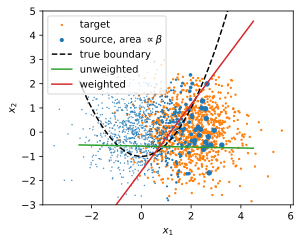

In [6]:
x1 = np.linspace(-2.5, 4.5, 50)
d2l.set_figsize((4.5, 3.5))
d2l.plt.scatter(*X_tgt.T, s=2, c='C1', label='target')
d2l.plt.scatter(*X_src.T, s=np.clip(beta, 0.2, 20), c='C0',
                label=r'source, area $\propto \beta$')
d2l.plt.plot(x1, 0.5 * x1**2 - 1, 'k--', label='true boundary')
for name, fmt in [('unweighted', 'C2'), ('weighted', 'C3')]:
    (w1, w2), b = models[name]
    d2l.plt.plot(x1, -(w1 * x1 + b) / w2, fmt, label=name)
d2l.plt.xlabel('$x_1$'), d2l.plt.ylabel('$x_2$'), d2l.plt.ylim(-3, 5)
d2l.plt.legend();

The unweighted boundary is a nearly horizontal line at about $x_2 = -0.6$,
the best line for the bottom of the parabola, where most source examples
lie. Near $(2, 0)$ the parabola rises steeply, and this line assigns $y = 1$
to the many target points above it but below the parabola. The weighted
boundary rises with a slope between about 1 and 2 along the right arm of the
parabola. The large dots at the right edge of the source cloud determine
it; the source points near the origin carry almost no weight.

## Label Shift Correction

Under label shift each class keeps its appearance, $p(\mathbf{x} \mid y)$,
and only the class proportions change. The argument that gave
the equation, with the weight now on the label,
gives

$$R_T[f] = \sum_{y} p_T(y) \int l(f(\mathbf{x}), y)\, p(\mathbf{x} \mid y) \;d\mathbf{x} = \mathbb{E}_{(\mathbf{x}, y) \sim p_S}\left[\frac{p_T(y)}{p_S(y)}\, l(f(\mathbf{x}), y)\right].$$

Each training example is weighted by $\beta_i = p_T(y^{(i)})/p_S(y^{(i)})$,
the ratio of how common its class is in the target and in the source, and
the model is again trained by weighted empirical risk minimization. The
source proportions $p_S(y)$ are the class frequencies of the training
labels. The target proportions $p_T(y)$ are unknown, since the target comes
without labels.

### Estimating the Target Class Proportions

Any classifier trained on the source can estimate the target proportions,
provided we know how it errs. In that section we counted a
classifier's errors in a confusion matrix, whose entry $(i, j)$ is the
number of examples of true class $j$ that were predicted as class $i$.
Dividing each column by the number of examples of its class gives the matrix
$\mathbf{C} \in \mathbb{R}^{q \times q}$ with entries

$$C_{ij} = P(\hat{y} = i \mid y = j),$$

the probability that an example of class $j$ is predicted as class $i$.
Each column of $\mathbf{C}$ sums to 1. We estimate $\mathbf{C}$ on a
labeled validation set from the source.

Under label shift, $\mathbf{C}$ is the same on the target: the prediction
$\hat{y}$ depends only on $\mathbf{x}$, and the inputs of each class have the
same distribution in both domains. Let $\mu_i$ be the fraction of target
inputs that the classifier assigns to class $i$, which needs no labels. By
the law of total probability,

$$\mu_i = \sum_{j=1}^q P(\hat{y} = i \mid y = j)\, p_T(y = j) = \sum_{j=1}^q C_{ij}\, p_T(y = j), \quad \textrm{that is,} \quad \mathbf{C}\, \mathbf{p}_T = \boldsymbol{\mu},$$

where the vectors $\mathbf{p}_T$ and $\boldsymbol{\mu}$ collect the $q$
target class proportions and prediction frequencies. The predictions we
observe on the target are the true target proportions mixed by the
classifier's errors. If $\mathbf{C}$ is invertible,
$\mathbf{p}_T = \mathbf{C}^{-1} \boldsymbol{\mu}$ undoes the mixing.

Consider a screening test validated on a source sample with equally many
healthy ($y = 0$) and sick ($y = 1$) patients. It detects 84% of the sick
and wrongly flags 16% of the healthy, so with rows and columns ordered
(healthy, sick),

$$\mathbf{C} = \begin{pmatrix} 0.84 & 0.16 \\ 0.16 & 0.84 \end{pmatrix}.$$

In the target population the test flags 23% of patients,
$\boldsymbol{\mu} = (0.77, 0.23)$. Writing $p$ for the target fraction of
sick patients, the second row of the equation reads
$0.16\,(1 - p) + 0.84\,p = 0.23$, so $p = 0.07/0.68 \approx 0.10$. The 23%
flagged overstates the prevalence because false alarms among the many
healthy patients, $0.16 \times 0.9 \approx 0.14$ of all patients, outnumber
the true alarms, $0.84 \times 0.1 \approx 0.08$. Retraining then weights
each sick training example by $0.1/0.5 = 0.2$ and each healthy one by
$0.9/0.5 = 1.8$.

We check the estimator on simulated data with a known answer. The input is
a single number with $x \mid y \sim \mathcal{N}(2y - 1, 1)$ in both domains,
which is the label shift assumption. The source is balanced, 10% of the
target is sick, and the classifier predicts "sick" when $x > 0$, the best
rule for the balanced source.

In [7]:
def sample(n, prevalence):
    """Labels with P(y = 1) = prevalence; x | y ~ N(2y - 1, 1) in every domain."""
    y = (rng.random(n) < prevalence).astype(int)
    return rng.normal(2 * y - 1, 1), y

x_val, y_val = sample(10000, 0.5)    # labeled validation data from the source
x_new, _ = sample(10000, 0.1)        # target data; its labels stay unused
predict = lambda x: (x > 0).astype(int)
C = np.array([[(predict(x_val[y_val == j]) == i).mean() for j in (0, 1)]
              for i in (0, 1)])
mu = np.array([(predict(x_new) == i).mean() for i in (0, 1)])
print('C =', C.round(2).tolist(), '  mu =', mu.round(3).tolist())
print('estimated target p(y) =', np.linalg.solve(C, mu).round(3).tolist())

C = [[0.84, 0.14], [0.16, 0.86]]   mu = [0.767, 0.233]
estimated target p(y) = [0.894, 0.106]


The estimated confusion matrix matches the worked example, since a sick
patient's $x$ exceeds 0 with probability about 0.84. Between about 21% and
24% of the target inputs are predicted sick, close to the 23% of the worked
example, while the estimated fraction of sick patients lies between about
0.08 and 0.12 across runs, around the true 0.10.

The estimate needs the label shift assumption, no target class that is
absent from the source, and an invertible $\mathbf{C}$. Invertibility holds
when the classifier gets the majority of each class right,
$C_{jj} > \frac{1}{2}$ for every $j$ (exercise
4); when
$\mathbf{C}$ is nearly singular, small sampling errors in $\boldsymbol{\mu}$
and in the estimated $\mathbf{C}$ become large errors in $\mathbf{p}_T$.
For a rare class the solution can even come out negative. In the simulation
above with a prevalence of 1% instead of 10% and 1,000 target examples,
about 30% of the runs estimate a negative fraction of sick patients. In
practice one sets negative estimates to 0 and rescales the others to sum to
1, or solves a least-squares problem restricted to proportions. Adjusting a classifier to new class
proportions goes back at least to @Saerens.Latinne.Decaestecker.2002;
@Lipton.Wang.Smola.2018 showed that the confusion-matrix estimate is
consistent for any fixed classifier with invertible $\mathbf{C}$.

## Concept Shift and Feedback

Reweighting fails in two remaining cases: when the labeling rule itself
changes, and when the model's own decisions change the data.

### Updating with Fresh Labels

Concept shift changes $p(y \mid \mathbf{x})$, the very relation that the
model estimates. Unlabeled target data cannot reveal it when the inputs keep
their distribution, and reweighting old examples cannot repair it, because
their labels are no longer right. Only new labeled data help. When the change
is gradual, as with news whose topics change from week to week, a common
response is to keep the current parameters and continue training on recent
labeled examples, so that the model follows the change. When the change is
abrupt, as when new diagnostic criteria take effect, examples labeled under
the old definition describe a different task, and the model must be
retrained on data labeled under the new one. Either way, we notice the
change only by monitoring the model's accuracy on freshly labeled examples.

### Decisions That Change the Data

Deploying a model turns its predictions into decisions, and decisions can
change the data that the model sees next. The footwear model of the opening
changed how applicants dressed. In predictive policing the effect acts on
the labels (the figure). Patrols are sent where the
model forecasts crime, more patrols record more of the crimes committed
there, and the retrained model sends still more patrols. Recorded crime
measures where the police looked as well as where crimes happened, so the
loop can widen a small initial difference between two neighborhoods with the
same crime rate.

![A feedback loop in predictive policing. Predictions decide where patrols go, patrols decide which crimes are recorded, and the records become the next training data.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-clf-feedback-loop.svg)

None of the corrections in this section applies here: reweighting assumes a
target distribution that exists independently of the model, while here the
model helps produce it. Detecting the loop requires data that the model's
decisions did not select, for instance from patrols sent to randomly chosen
neighborhoods. Beyond detection lie questions that statistics cannot
settle: whether the decision system serves an appropriate goal, and whether
its errors fall unequally on different groups. A medical classifier must be
judged by the costs of its errors in each population it serves, not by its
average accuracy, and tuning its thresholds to those costs does not by
itself make it fair, since formal definitions of fairness can conflict.
Problems in which a learner's actions determine what it observes next are
the subject of reinforcement learning (that section).

## Summary

A test set predicts performance in deployment only when deployment data come
from the same distribution, and nothing transfers without an assumption
about what stays fixed. Under covariate shift the labeling rule stays fixed,
and weighting each training example by $p_T(\mathbf{x})/p_S(\mathbf{x})$,
estimated by a classifier that tells target inputs from source inputs,
corrects training; in our example it raised target accuracy from about half
to about 90% or more. It requires the source to cover the target and loses
effective sample size as the weights spread. Under label shift each class
keeps its appearance, and the weights $p_T(y)/p_S(y)$ come from solving
$\mathbf{C}\,\mathbf{p}_T = \boldsymbol{\mu}$. Concept shift requires fresh
labels, and when a model's decisions change its own data, statistical
correction must be complemented by an analysis of the decisions.

## Exercises

1. **Feedback loops.** A search engine changes how it ranks results. It
   then retrains its ranker on the clicks logged under the new ranking,
   with a query-document pair as the input $\mathbf{x}$ and a click as the
   label $y$.
    1. Describe one way users and one way advertisers might respond to
       the new ranking.
    1. For each response, state whether it changes $p(\mathbf{x})$,
       $p(y \mid \mathbf{x})$, or both in the next training set. Then
       decide whether the response is an instance of Goodhart's law.

1. **Missing support.** Suppose that $p_S(\mathbf{x}) = 0$ on a region
   $\mathcal{A}$ of inputs that has probability $\pi > 0$ under the target,
   and that $p_S(\mathbf{x}) > 0$ everywhere else. Define
   $\beta(\mathbf{x}) = p_T(\mathbf{x})/p_S(\mathbf{x})$ outside
   $\mathcal{A}$.
    1. Show that the weighted source risk
       $\mathbb{E}_{(\mathbf{x}, y) \sim p_S}[\beta(\mathbf{x})\, l(f(\mathbf{x}), y)]$
       equals the target risk with the contribution of $\mathcal{A}$
       removed. Write the missing term as $\pi$ times a conditional
       expectation.
    1. Explain why no choice of weights on source examples can recover the
       missing term. Construct two models that agree outside
       $\mathcal{A}$ and have the same weighted source risk but different
       target risks.

1. [code] **When reweighting fails.** The code of
   that section (`fit_logreg`, `X_src`,
   `X_tgt`, `label`) places the target mean at $(2, 0)$. Sweep the target
   mean over $(s, 0)$ for $s \in \{0, 0.5, 1, 2, 3, 4, 6\}$, keeping
   $n = 1000$ and the labeling rule fixed.
    1. For each $s$, report the accuracy of the domain classifier $h$ on
       held-out pooled data, and interpret its growth with $s$ in terms of
       how detectable the shift is.
    1. For each $s$, record the target accuracy of the unweighted,
       weighted, and clipped ($c = 5$) models, and of always predicting the
       most common target class. Explain why target accuracy alone cannot
       show whether reweighting worked at large $s$.

1. **The label shift system.** Let $\mathbf{C}$ be the column-normalized
   confusion matrix of the equation.
    1. Show that $\mathbf{C}$ is invertible whenever $C_{jj} > \frac{1}{2}$
       for every class $j$. Hint: suppose that $\mathbf{v}^\top \mathbf{C} = \mathbf{0}$
       for some $\mathbf{v} \neq \mathbf{0}$, look at the column $j$ for
       which $|v_j|$ is largest, and use that the column sums to 1.
    1. Give an example of a classifier for which $\mathbf{C}$ is singular,
       and describe what $\boldsymbol{\mu}$ can still reveal about
       $\mathbf{p}_T$ in that case.
    1. For two classes, show that an error $\delta$ in the fraction
       $\mu_1$ of positive predictions changes the estimated fraction of
       positives by $\delta/(C_{11} - C_{10})$. Using the standard error
       $\sqrt{\mu_1 (1 - \mu_1)/m}$ of a fraction estimated from $m$ target
       inputs, find how many target inputs the screening example needs for
       a standard error of 0.01 in the estimated fraction of sick patients.
       Repeat for a weaker test with $C_{11} = 0.6$ and $C_{10} = 0.4$ on
       the same population.

1. **Features missing at serving time.** A model forecasts a store's daily
   revenue at the start of each day. Its training records hold each past
   day's final customer count as a feature, and the model performs well in
   offline evaluation on held-out records. At serving time the pipeline
   fills this feature with the number of customers counted so far that day.
    1. Compare the distribution of this feature, and its relation to
       revenue, in the training records and at serving time. State which
       of the section's shift assumptions, if any, holds between the two.
    1. Explain why the offline evaluation could not reveal this mismatch,
       and why the reweighting of
       that section cannot repair it.
    1. Propose a rule for selecting training features that avoids this
       failure.

    *Adapted from Google's Machine Learning Crash Course,
    ["Monitoring pipelines"](https://developers.google.com/machine-learning/crash-course/production-ml-systems/monitoring).*

1. [extended] **Real-world shifts.** The WILDS benchmark
   [@Koh.Sagawa.Marklund.ea.2021] collects distribution shifts that
   occur in practice. Pick two of its tasks, for example a
   hospital-to-hospital or a camera-trap-to-camera-trap shift, and classify
   each as closer to covariate shift, label shift, or neither, justifying
   your classification from how the data were collected. If you can
   download one of the smaller WILDS datasets, train a linear baseline and
   report its in-distribution versus out-of-distribution accuracy gap.

1. [code] **Learned versus true weights.** ● Reuse the sweep of exercise
   3
   over target means $(s, 0)$.
    1. Derive the true log-ratio $\log(p_T(\mathbf{x})/p_S(\mathbf{x}))$ as
       a function of $s$, and compare it with the learned $h$ at each $s$.
       Explain how the domain classifier can reach high accuracy at large
       $s$ while $h$ is far from the true log-ratio.
    1. Show that under the source the true weights satisfy
       $\mathbb{E}[\beta(\mathbf{x})] = 1$ and $\mathbb{E}[\beta(\mathbf{x})^2] = e^{s^2}$, so
       that for large $n$ their effective sample size is about
       $n e^{-s^2}$. Evaluate this for $n = 1000$ and $s = 1, 2, 3$.
    1. For each $s$, compute the effective sample size of the true weights
       and of the learned weights on the actual source sample. Explain why
       at $s = 2$ the sample value is usually much larger than
       $1000\, e^{-4} \approx 18$, and what this means for judging the
       reliability of a reweighted fit from the sample alone. Does clipping
       at $c = 5$ repair the shortage?

1. **Shift assumptions from unlabeled data.** ● In a binary source domain,
   $p_S(y = 1) = p_S(y = 0) = \frac{1}{2}$, and the scalar input satisfies
   $x \mid y = 1 \sim \mathcal{N}(1, 1)$ and
   $x \mid y = 0 \sim \mathcal{N}(-1, 1)$. Hence
   $p_S(y = 1 \mid x) = 1/(1 + \exp(-2x))$. Unlabeled target inputs follow
   the mixture

   $$p_T(x) = 0.8\, \mathcal{N}(x; 1, 1) + 0.2\, \mathcal{N}(x; -1, 1).$$

    1. Assume label shift. Give $p_T(y = 1)$ and the threshold on $x$ of
       the Bayes-optimal target classifier.
    1. Assume instead covariate shift with the same $p_T(x)$. Compute
       $p_T(y = 1)$ numerically and give the Bayes-optimal threshold.
    1. Use your results to explain why no statistic of the unlabeled
       target sample can decide which of the two corrections of this
       section applies.


[Discussions](https://d2l.discourse.group/t/105)